## Imports and Setup

In [1]:
# Install dependencies
!pip install -q timm transformers ranger21

# Core imports
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
import random
import warnings
warnings.filterwarnings('ignore')

# Torch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# timm for ResNeSt
import timm

# transformers for SegFormer
from transformers import SegformerForSemanticSegmentation

# Metrics
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score

# Progress bar
from tqdm.auto import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

2026-01-30 14:32:23.745864: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769783544.070795      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769783544.171913      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769783545.003979      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769783545.004026      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769783545.004029      55 computation_placer.cc:177] computation placer alr

CUDA available: True
Device: Tesla P100-PCIE-16GB


## Configuration

In [2]:
class ConfigClassification:
    TARGET_SIZE = 384
    NUM_CLASSES = 3
    INPUT_CHANNELS = 1
    N_FOLDS = 5
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    WEIGHTS_PATH = "/kaggle/input/my-resnest50"

class ConfigSegmentation:
    TARGET_SIZE = 512
    NUM_CLASSES = 2
    INPUT_CHANNELS = 1
    N_FOLDS = 3
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    WEIGHTS_PATH = "/kaggle/input/model-weights/weights/1b"

INPUT_DIRECTORY = '/kaggle/input/breast-lesions/'
TEST_IMG_DIRECTORY = Path(INPUT_DIRECTORY) / 'test' / 'images'
TEST_LABELS_PATH = INPUT_DIRECTORY + 'test/test_metadata.xlsx'

print(f"\n{'='*80}")
print(f"📋 CONFIGURATION")
print(f"{'='*80}")
print(f"\n🔬 Classification (Phase 1):")
print(f"   Target size: {ConfigClassification.TARGET_SIZE}")
print(f"   Num classes: {ConfigClassification.NUM_CLASSES}")
print(f"   Weights path: {ConfigClassification.WEIGHTS_PATH}")
print(f"\n🎯 Segmentation (Phase 2):")
print(f"   Target size: {ConfigSegmentation.TARGET_SIZE}")
print(f"   Weights path: {ConfigSegmentation.WEIGHTS_PATH}")
print(f"\n📂 Data paths:")
print(f"   Test images: {TEST_IMG_DIRECTORY}")
print(f"   Test labels: {TEST_LABELS_PATH}")
print(f"{'='*80}\n")


📋 CONFIGURATION

🔬 Classification (Phase 1):
   Target size: 384
   Num classes: 3
   Weights path: /kaggle/input/my-resnest50

🎯 Segmentation (Phase 2):
   Target size: 512
   Weights path: /kaggle/input/model-weights/weights/1b

📂 Data paths:
   Test images: /kaggle/input/breast-lesions/test/images
   Test labels: /kaggle/input/breast-lesions/test/test_metadata.xlsx



## Preprocessing Functions (Identical to Training)

In [3]:

def has_colors(img,
            sat_thresh=40,
            delta_thresh=20,
            min_region_area=20,
            max_region_area_ratio=0.1,
            max_aspect_ratio=5,
            mean_delta_thresh=15,
            dilate_iters=1,
            erode_iters=1):
    b, g, r = cv2.split(img)
    r = r.astype(np.int16)
    g = g.astype(np.int16)
    b = b.astype(np.int16)

    delta = np.maximum.reduce([np.abs(r - g), np.abs(r - b), np.abs(g - b)])
    mask_rgb = delta > delta_thresh

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask_sat = hsv[:, :, 1] > sat_thresh

    mask = np.logical_and(mask_rgb, mask_sat).astype(np.uint8) * 255
    if np.sum(mask) == 0:
        return False, mask

    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1))
    kernel_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    mask = cv2.dilate(mask, kernel_h, iterations=dilate_iters)
    mask = cv2.dilate(mask, kernel_v, iterations=dilate_iters)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    h, w = mask.shape
    img_area = h * w

    filtered = np.zeros_like(mask)
    rect = np.zeros_like(mask)
    detected = False

    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        x, y, width, height = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP], stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        aspect_ratio = max(width / (height + 1e-5), height / (width + 1e-5))

        region_mask = labels == i
        mean_delta = delta[region_mask].mean()
        std_delta = delta[region_mask].std()
        mean_sat = hsv[:, :, 1][region_mask].mean()
        std_sat = hsv[:, :, 1][region_mask].std()
        
        if (min_region_area < area < max_region_area_ratio * img_area):
            filtered[region_mask] = 255
            detected = True
    
        elif ((aspect_ratio > max_aspect_ratio) and 
            (mean_delta > mean_delta_thresh) and std_delta < 1 and 
            mean_sat > 25 and std_sat < 1):
            rect[region_mask] = 255
            detected = True

    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (200, 1))
    kernel_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 200))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    rect = cv2.dilate(rect, kernel_h, iterations=dilate_iters)
    rect = cv2.dilate(rect, kernel_v, iterations=dilate_iters)
    rect = cv2.morphologyEx(rect, cv2.MORPH_CLOSE, kernel_close)

    kernel_corner = cv2.getStructuringElement(cv2.MORPH_RECT, (10, 10))
    rect = cv2.morphologyEx(rect, cv2.MORPH_CLOSE, kernel_corner)

    if erode_iters > 0:
        rect = cv2.erode(rect, kernel_close, iterations=erode_iters)
    
    filtered = cv2.bitwise_or(filtered, rect)

    return detected, filtered


def remove_ink(img, ink_mask):
    return cv2.inpaint(img, ink_mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)


def inpaint(img):
    hasColors, color_mask = has_colors(img)
    if hasColors:
        return remove_ink(img, color_mask)
    return img


def square_pad_resize(img, target_size, pad_value=0):
    h, w = img.shape[:2]
    
    if h == w and h == target_size:
        return img

    max_dim = max(h, w)
    delta_w = max_dim - w
    delta_h = max_dim - h
    top, bottom = delta_h // 2, delta_h - (delta_h // 2)
    left, right = delta_w // 2, delta_w - (delta_w // 2)
    
    img_padded = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=pad_value)
    img_resized = cv2.resize(img_padded, (target_size, target_size), interpolation=cv2.INTER_CUBIC)
    
    return img_resized


def apply_median_filter(image, kernel_size=5):
    return cv2.medianBlur(image.astype(np.uint8), kernel_size)


def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)


def apply_zscore_normalization(image):
    image = image.astype(np.float32)
    mean = np.mean(image)
    std = np.std(image)
    if std == 0:
        return image - mean
    return (image - mean) / std


print("✅ Preprocessing functions loaded")

✅ Preprocessing functions loaded


In [4]:
def segmentation_crop(img, mask, output_size=512):
    h, w = img.shape[:2]
    
    if mask is not None and np.any(mask > 0):
        coords = np.where(mask > 0)
        y_center = int(np.mean(coords[0]))
        x_center = int(np.mean(coords[1]))
    else:
        y_center, x_center = h // 2, w // 2
    
    crop_size = max(h, w)
    half_crop = crop_size // 2
    
    x1 = x_center - half_crop
    x2 = x_center + half_crop
    y1 = y_center - half_crop
    y2 = y_center + half_crop
    
    if x1 < 0:
        x2 -= x1
        x1 = 0
    if y1 < 0:
        y2 -= y1
        y1 = 0
    if x2 > w:
        x1 -= (x2 - w)
        x2 = w
    if y2 > h:
        y1 -= (y2 - h)
        y2 = h

    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)

    crop_img = img[y1:y2, x1:x2]
    crop_mask = mask[y1:y2, x1:x2] if mask is not None else None

    final_img = cv2.resize(crop_img, (output_size, output_size), interpolation=cv2.INTER_CUBIC)
    final_mask = cv2.resize(crop_mask, (output_size, output_size), interpolation=cv2.INTER_NEAREST) if crop_mask is not None else None

    return final_img, final_mask


def resize_with_padding_seg(img, target_size=512):
    h, w = img.shape[:2]
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_CUBIC)
    
    pad_h, pad_w = target_size - new_h, target_size - new_w
    pad_top, pad_left = pad_h // 2, pad_w // 2
    pad_bottom, pad_right = pad_h - pad_top, pad_w - pad_left
    
    img_padded = cv2.copyMakeBorder(
        img_resized, pad_top, pad_bottom, pad_left, pad_right, 
        cv2.BORDER_CONSTANT, value=0
    )
    
    pad_info = (pad_top, pad_left, new_h, new_w, h, w)
    return img_padded, pad_info


print("✅ Segmentation preprocessing functions loaded")

✅ Segmentation preprocessing functions loaded


In [5]:
class UltrasoundAugmentation:
    def __init__(self, p=0.5):
        self.p = p
    
    def __call__(self, img_tensor):
        flip_h = random.random() < 0.5
        flip_v = random.random() < 0.5
        apply_rotation = random.random() < self.p
        rotation_angle = random.uniform(-15, 15) if apply_rotation else 0
        
        # Horizontal Flip
        if flip_h:
            img_tensor = torch.flip(img_tensor, dims=[2])
        
        # Vertical Flip
        if flip_v:
            img_tensor = torch.flip(img_tensor, dims=[1])
        
        # Random Rotation
        if apply_rotation:
            pil_img = transforms.ToPILImage()(img_tensor)
            pil_img = transforms.functional.rotate(pil_img, rotation_angle, fill=0)
            img_tensor = transforms.ToTensor()(pil_img)
            
        # Elastic Transform
        if random.random() < self.p:
            alpha_val = random.uniform(2.0, 5.0)
            sigma_val = random.uniform(4.0, 8.0)
            elastic = transforms.ElasticTransform(alpha=alpha_val, sigma=sigma_val, fill=0)
            img_tensor = elastic(img_tensor)
        
        # Brightness adjustment
        if random.random() < self.p:
            brightness_factor = random.uniform(0.9, 1.1)
            img_tensor = transforms.functional.adjust_brightness(
                transforms.ToPILImage()(img_tensor), brightness_factor
            )
            img_tensor = transforms.ToTensor()(img_tensor)

        return img_tensor


print("✅ Training augmentation class loaded")

✅ Training augmentation class loaded


## Load Test Data

In [6]:
def load_test_data(csv_path, images_dir):

    df = pd.read_excel(csv_path)
    
    samples = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading test data"):
        img_name = row['US']
        mask_name = row['MASK']
        label = row['LABEL']
        
        img_path = str(Path(images_dir) / img_name)
        mask_path = str(Path(images_dir) / mask_name)
        
        samples.append({
            'img_path': img_path,
            'mask_path': mask_path,
            'img_name': img_name,
            'label': label
        })
    
    return samples

test_samples = load_test_data(TEST_LABELS_PATH, TEST_IMG_DIRECTORY)

label_counts = np.bincount([s['label'] for s in test_samples])
print(f"\n{'='*80}")
print(f"📊 TEST DATA LOADED")
print(f"{'='*80}")
print(f"Total samples: {len(test_samples)}")
print(f"  Benign (0): {label_counts[0]}")
print(f"  Malignant (1): {label_counts[1]}")
print(f"  Normal (2): {label_counts[2] if len(label_counts) > 2 else 0}")
print(f"{'='*80}\n")

Loading test data:   0%|          | 0/308 [00:00<?, ?it/s]


📊 TEST DATA LOADED
Total samples: 308
  Benign (0): 134
  Malignant (1): 75
  Normal (2): 99



## Visualize Preprocessing Pipeline

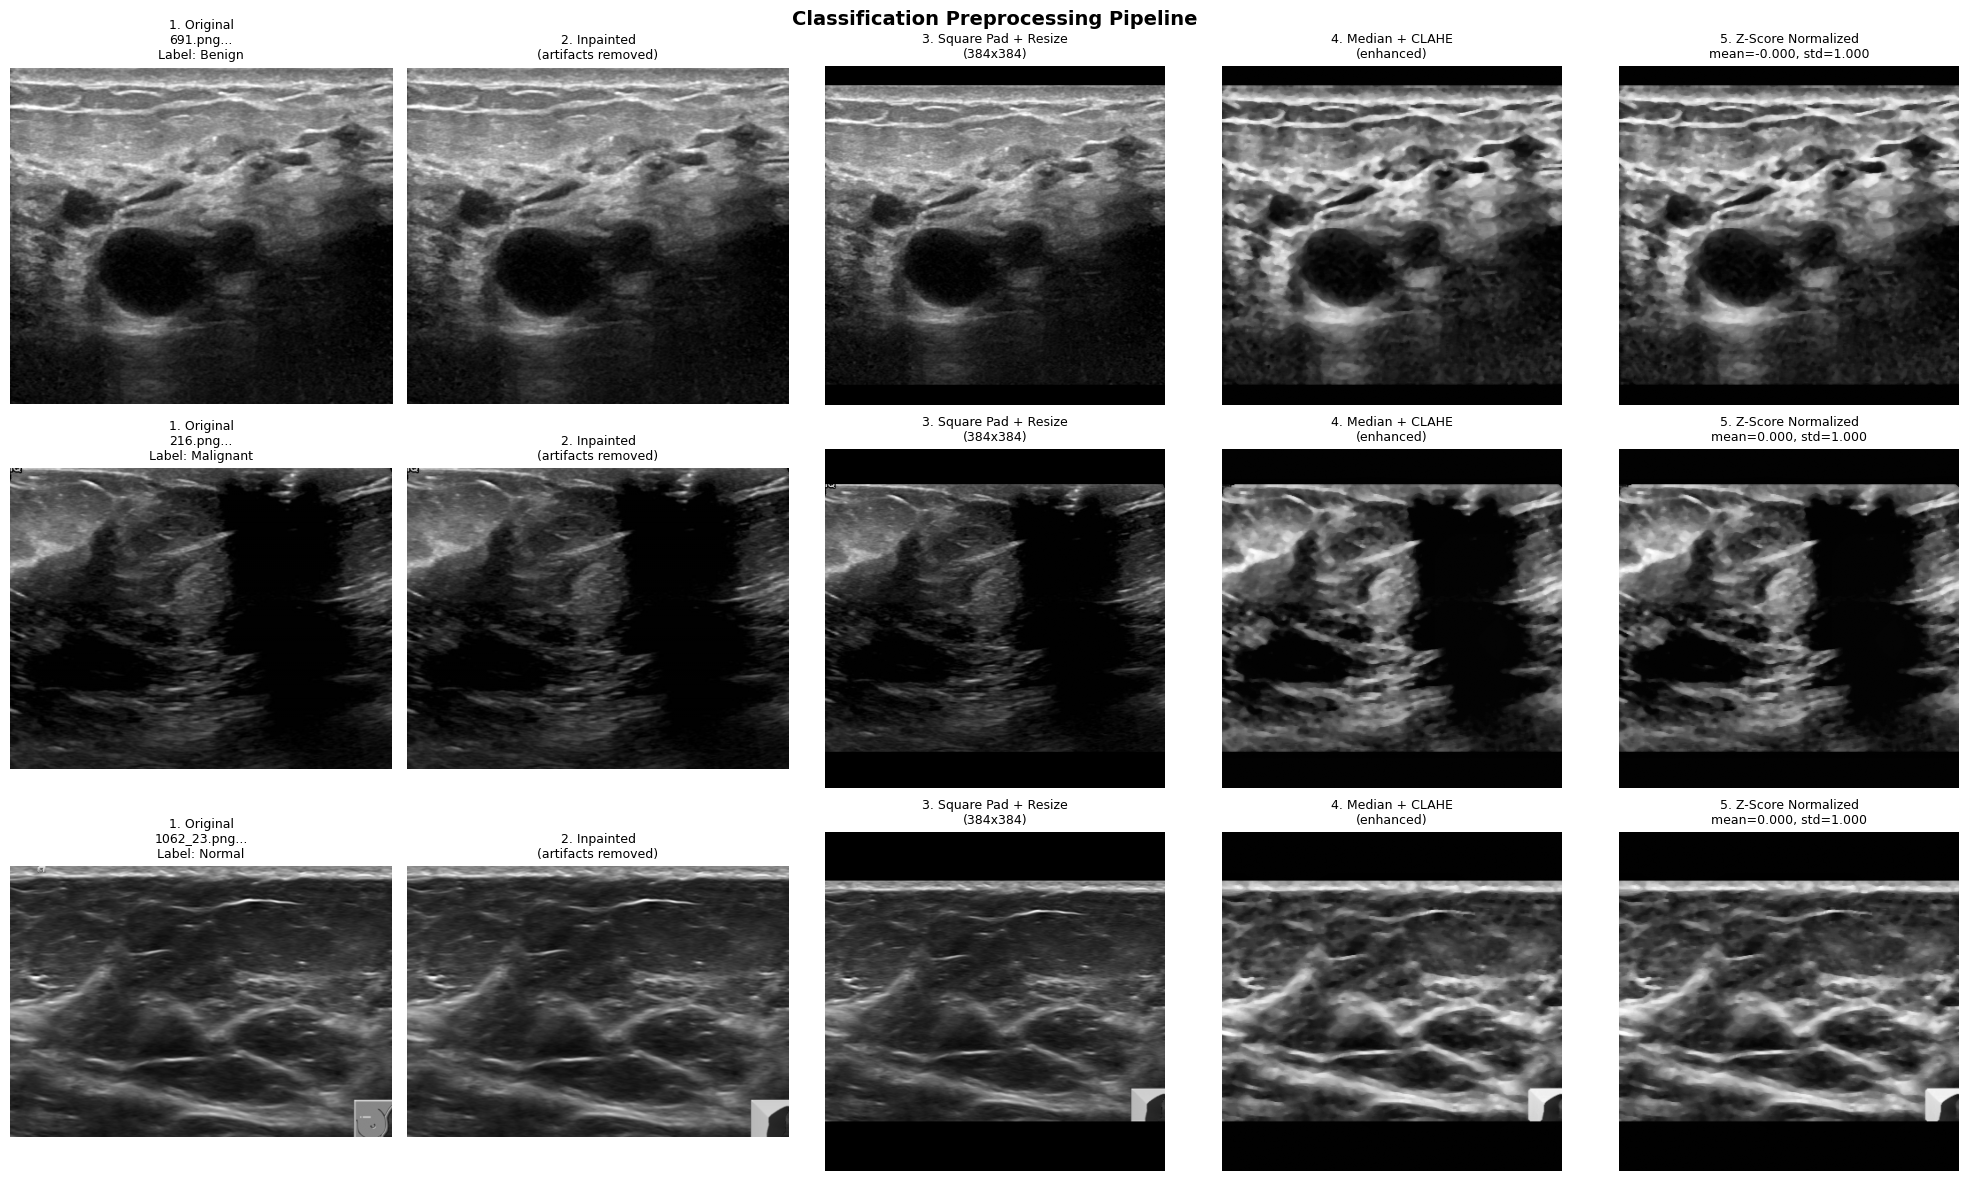

✅ Preprocessing visualization complete


In [7]:
label_map = {0: 'Benign', 1: 'Malignant', 2: 'Normal'}

samples_by_label = defaultdict(list)
for s in test_samples:
    samples_by_label[s['label']].append(s)

vis_samples = []
for label in [0, 1, 2]:
    if label in samples_by_label and len(samples_by_label[label]) > 0:
        vis_samples.append(random.choice(samples_by_label[label]))

n_vis = len(vis_samples)

fig, axes = plt.subplots(n_vis, 5, figsize=(20, 4*n_vis))
if n_vis == 1:
    axes = axes.reshape(1, -1)

for i, sample in enumerate(vis_samples):
    img_bgr = cv2.imread(sample['img_path'])
    img_gray_orig = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    axes[i, 0].imshow(img_gray_orig, cmap='gray')
    axes[i, 0].set_title(f"1. Original\n{sample['img_name'][:25]}...\nLabel: {label_map[sample['label']]}", fontsize=9)
    axes[i, 0].axis('off')
    
    img_inpainted = inpaint(img_bgr)
    img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
    axes[i, 1].imshow(img_gray, cmap='gray')
    axes[i, 1].set_title(f"2. Inpainted\n(artifacts removed)", fontsize=9)
    axes[i, 1].axis('off')
    
    img_resized = square_pad_resize(img_gray, ConfigClassification.TARGET_SIZE)
    axes[i, 2].imshow(img_resized, cmap='gray')
    axes[i, 2].set_title(f"3. Square Pad + Resize\n({ConfigClassification.TARGET_SIZE}x{ConfigClassification.TARGET_SIZE})", fontsize=9)
    axes[i, 2].axis('off')
    
    img_filtered = apply_median_filter(img_resized)
    img_clahe = apply_clahe(img_filtered)
    axes[i, 3].imshow(img_clahe, cmap='gray')
    axes[i, 3].set_title(f"4. Median + CLAHE\n(enhanced)", fontsize=9)
    axes[i, 3].axis('off')
    
    img_normalized = apply_zscore_normalization(img_clahe)
    img_vis = (img_normalized - img_normalized.min()) / (img_normalized.max() - img_normalized.min() + 1e-8)
    axes[i, 4].imshow(img_vis, cmap='gray')
    axes[i, 4].set_title(f"5. Z-Score Normalized\nmean={img_normalized.mean():.3f}, std={img_normalized.std():.3f}", fontsize=9)
    axes[i, 4].axis('off')

plt.suptitle('Classification Preprocessing Pipeline', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Preprocessing visualization complete")

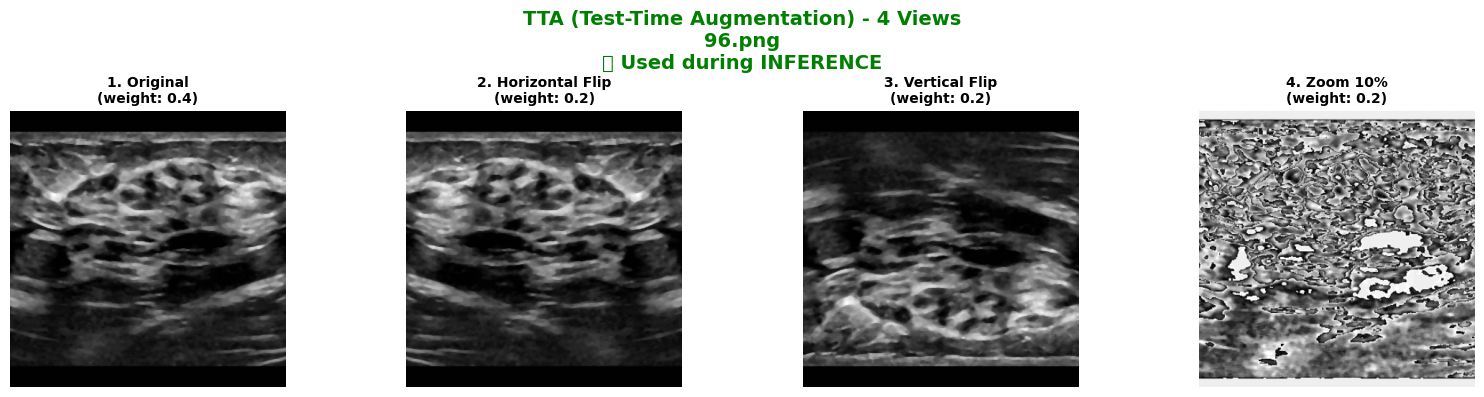

✅ TTA visualization complete
   Final prediction = weighted average of 4 views (0.4, 0.2, 0.2, 0.2)


In [8]:
demo_sample = random.choice(test_samples)

img_bgr = cv2.imread(demo_sample['img_path'])
img_inpainted = inpaint(img_bgr)
img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
img_resized = square_pad_resize(img_gray, ConfigClassification.TARGET_SIZE)
img_filtered = apply_median_filter(img_resized)
img_clahe = apply_clahe(img_filtered)
img_normalized = apply_zscore_normalization(img_clahe)

img_tensor = torch.from_numpy(img_normalized).float().unsqueeze(0).unsqueeze(0)  # (1, 1, H, W)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

img_vis = (img_normalized - img_normalized.min()) / (img_normalized.max() - img_normalized.min() + 1e-8)
axes[0].imshow(img_vis, cmap='gray')
axes[0].set_title('1. Original\n(weight: 0.4)', fontsize=10, fontweight='bold')
axes[0].axis('off')

img_hflip = torch.flip(img_tensor, dims=[3])[0, 0].numpy()
img_hflip_vis = (img_hflip - img_hflip.min()) / (img_hflip.max() - img_hflip.min() + 1e-8)
axes[1].imshow(img_hflip_vis, cmap='gray')
axes[1].set_title('2. Horizontal Flip\n(weight: 0.2)', fontsize=10, fontweight='bold')
axes[1].axis('off')

img_vflip = torch.flip(img_tensor, dims=[2])[0, 0].numpy()
img_vflip_vis = (img_vflip - img_vflip.min()) / (img_vflip.max() - img_vflip.min() + 1e-8)
axes[2].imshow(img_vflip_vis, cmap='gray')
axes[2].set_title('3. Vertical Flip\n(weight: 0.2)', fontsize=10, fontweight='bold')
axes[2].axis('off')

b, c, h, w = img_tensor.shape
zoom_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(int(h * 1.1)),
    transforms.CenterCrop(h),
    transforms.ToTensor()
])
img_zoom = zoom_transform(img_tensor[0, 0].cpu()).squeeze(0).numpy()  # Remove channel dim
img_zoom_vis = (img_zoom - img_zoom.min()) / (img_zoom.max() - img_zoom.min() + 1e-8)
axes[3].imshow(img_zoom_vis, cmap='gray')
axes[3].set_title('4. Zoom 10%\n(weight: 0.2)', fontsize=10, fontweight='bold')
axes[3].axis('off')

plt.suptitle(f'TTA (Test-Time Augmentation) - 4 Views\n{demo_sample["img_name"]}\n✅ Used during INFERENCE', 
             fontsize=14, fontweight='bold', color='green')
plt.tight_layout()
plt.show()

print("✅ TTA visualization complete")
print("   Final prediction = weighted average of 4 views (0.4, 0.2, 0.2, 0.2)")

In [10]:
class GlobalResNeSt50(nn.Module):
    def __init__(self, num_classes=3, pretrained=False):
        super().__init__()
        
        self.model = timm.create_model('resnest50d', pretrained=pretrained)
        
        original_conv = self.model.conv1[0]
        
        new_conv = nn.Conv2d(
            in_channels=1, 
            out_channels=original_conv.out_channels,
            kernel_size=original_conv.kernel_size,
            stride=original_conv.stride,
            padding=original_conv.padding,
            bias=original_conv.bias is not None
        )
        
        with torch.no_grad():
            new_conv.weight[:] = torch.sum(original_conv.weight, dim=1, keepdim=True)
            
        self.model.conv1[0] = new_conv
        
        n_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(n_features, num_classes)
        )
        
    def forward(self, x):
        return self.model(x)


print("✅ GlobalResNeSt50 model defined")

✅ GlobalResNeSt50 model defined


In [11]:
clf_weights_dir = Path(ConfigClassification.WEIGHTS_PATH)

clf_weight_files = []
for fold_dir in sorted(clf_weights_dir.glob('fold_*')):
    weight_file = fold_dir / 'best_model.pth'
    if weight_file.exists():
        clf_weight_files.append(weight_file)

if len(clf_weight_files) == 0:
    clf_weight_files = sorted(clf_weights_dir.glob('*.pth')) + sorted(clf_weights_dir.glob('*.pt'))

if len(clf_weight_files) == 0:
    raise FileNotFoundError(f"❌ ERROR: No weight files found in {ConfigClassification.WEIGHTS_PATH}")

print(f"✅ Found {len(clf_weight_files)} classification model weights")
for wf in clf_weight_files:
    print(f"   - {wf}")

clf_models = []
for weights_file in clf_weight_files:
    model = GlobalResNeSt50(num_classes=ConfigClassification.NUM_CLASSES, pretrained=False)
    model = model.to(ConfigClassification.DEVICE)
    model.eval()
    
    try:
        checkpoint = torch.load(weights_file, map_location=ConfigClassification.DEVICE, weights_only=False)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'], strict=False)
        else:
            model.load_state_dict(checkpoint, strict=False)
        clf_models.append(model)
        print(f"✅ Loaded {weights_file.name}")
    except Exception as e:
        print(f"⚠️ Failed to load {weights_file.name}: {e}")

if len(clf_models) == 0:
    raise RuntimeError("❌ No classification models loaded!")

print(f"\n✅ Loaded {len(clf_models)} models for ensemble\n")

✅ Found 5 classification model weights
   - /kaggle/input/my-resnest50/best_model_fold0.pth
   - /kaggle/input/my-resnest50/best_model_fold1.pth
   - /kaggle/input/my-resnest50/best_model_fold2.pth
   - /kaggle/input/my-resnest50/best_model_fold3.pth
   - /kaggle/input/my-resnest50/best_model_fold4.pth
✅ Loaded best_model_fold0.pth
✅ Loaded best_model_fold1.pth
✅ Loaded best_model_fold2.pth
✅ Loaded best_model_fold3.pth
✅ Loaded best_model_fold4.pth

✅ Loaded 5 models for ensemble



In [12]:
print(f"{'='*80}")
print(f"🔬 PHASE 1: CLASSIFICATION INFERENCE (3-Class)")
print(f"{'='*80}\n")

def apply_tta_classification(img_tensor, models, device):
    tta_weights = [0.4, 0.2, 0.2, 0.2]  # [orig, hflip, vflip, zoom]
    
    imgs_orig = img_tensor.to(device)
    
    imgs_hflip = torch.flip(imgs_orig, dims=[3])
    
    imgs_vflip = torch.flip(imgs_orig, dims=[2])
    
    b, c, h, w = imgs_orig.shape
    zoom_transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize(int(h * 1.1)),
        transforms.CenterCrop(h),
        transforms.ToTensor()
    ])

    imgs_zoom = torch.stack([zoom_transform(img.squeeze(0).cpu()) for img in imgs_orig]).to(device)
    

    tta_batch = torch.cat([imgs_orig, imgs_hflip, imgs_vflip, imgs_zoom], dim=0)
    
    batch_ensemble_probs = torch.zeros(b, ConfigClassification.NUM_CLASSES, device=device)
    
    with torch.no_grad():
        for model in models:
            logits = model(tta_batch)
            probs = F.softmax(logits, dim=1)
            
            p_orig = probs[0:b]
            p_hflip = probs[b:2*b]
            p_vflip = probs[2*b:3*b]
            p_zoom = probs[3*b:4*b]
            
            model_avg = (p_orig * tta_weights[0] +
                        p_hflip * tta_weights[1] + 
                        p_vflip * tta_weights[2] + 
                        p_zoom * tta_weights[3])
            
            batch_ensemble_probs += model_avg
    
    final_probs = batch_ensemble_probs / len(models)
    return final_probs


classification_results = []

for sample in tqdm(test_samples, desc="Classification inference"):
    img_bgr = cv2.imread(sample['img_path'])
    img_inpainted = inpaint(img_bgr)
    img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
    img_resized = square_pad_resize(img_gray, ConfigClassification.TARGET_SIZE)
    img_filtered = apply_median_filter(img_resized)
    img_clahe = apply_clahe(img_filtered)
    img_normalized = apply_zscore_normalization(img_clahe)
    
    img_tensor = torch.from_numpy(img_normalized).unsqueeze(0).unsqueeze(0).float()
    
    probs = apply_tta_classification(img_tensor, clf_models, ConfigClassification.DEVICE)
    probs = probs[0].cpu().numpy()
    
    pred_class = np.argmax(probs)
    sample['pred_class'] = pred_class
    sample['probs'] = probs
    sample['prob_benign'] = probs[0]
    sample['prob_malignant'] = probs[1]
    sample['prob_normal'] = probs[2]
    
    classification_results.append({
        'US': sample['img_name'],
        'LABEL': int(pred_class),
        'GT_LABEL': sample['label'],
        'prob_benign': probs[0],
        'prob_malignant': probs[1],
        'prob_normal': probs[2]
    })

print(f"\n✅ Classification complete!")

🔬 PHASE 1: CLASSIFICATION INFERENCE (3-Class)



Classification inference:   0%|          | 0/308 [00:00<?, ?it/s]


✅ Classification complete!



📊 PHASE 1 RESULTS: CLASSIFICATION (3-Class)

✅ BALANCED ACCURACY: 0.8227 (82.27%)

Prediction Distribution:
  Benign (0): 141 (GT: 134)
  Malignant (1): 63 (GT: 75)
  Normal (2): 104 (GT: 99)


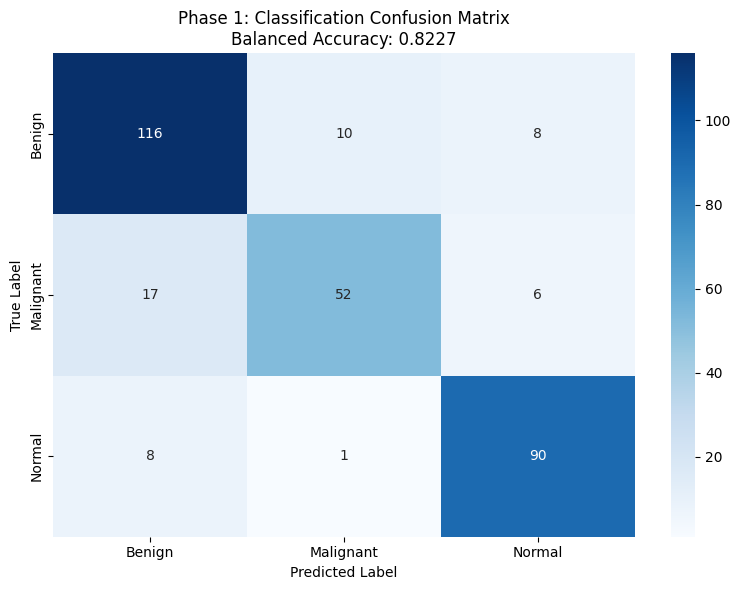

In [13]:
gt_labels = [s['label'] for s in test_samples]
pred_labels = [s['pred_class'] for s in test_samples]

ba_3class = balanced_accuracy_score(gt_labels, pred_labels)

cm = confusion_matrix(gt_labels, pred_labels)

print(f"\n{'='*80}")
print(f"📊 PHASE 1 RESULTS: CLASSIFICATION (3-Class)")
print(f"{'='*80}")
print(f"\n✅ BALANCED ACCURACY: {ba_3class:.4f} ({ba_3class*100:.2f}%)")
print(f"\nPrediction Distribution:")
print(f"  Benign (0): {pred_labels.count(0)} (GT: {gt_labels.count(0)})")
print(f"  Malignant (1): {pred_labels.count(1)} (GT: {gt_labels.count(1)})")
print(f"  Normal (2): {pred_labels.count(2)} (GT: {gt_labels.count(2)})")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Benign', 'Malignant', 'Normal'],
            yticklabels=['Benign', 'Malignant', 'Normal'])
plt.title(f'Phase 1: Classification Confusion Matrix\nBalanced Accuracy: {ba_3class:.4f}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

print(f"{'='*80}\n")

In [14]:
df_classification = pd.DataFrame({
    'US': [s['img_name'] for s in test_samples],
    'LABEL': [s['pred_class'] for s in test_samples]
})

print("\n📋 Classification Results DataFrame (US, LABEL):")
print(df_classification.head(10))
print(f"\nTotal rows: {len(df_classification)}")

output_path = '/kaggle/working/task1_classification_results.csv'
df_classification.to_csv(output_path, index=False)
print(f"\n✅ Classification results saved to: {output_path}")


📋 Classification Results DataFrame (US, LABEL):
        US  LABEL
0  589.png      0
1  731.png      0
2  445.png      0
3  396.png      0
4  452.png      0
5  242.png      1
6  878.png      0
7  261.png      1
8  451.png      0
9  217.png      0

Total rows: 308

✅ Classification results saved to: /kaggle/working/task1_classification_results.csv


---

# Phase 2: Segmentation (Benign/Malignant Only)

Using SegFormer ensemble on samples classified as Benign or Malignant

In [15]:
seg_samples = [s for s in test_samples if s['pred_class'] in [0, 1]]

print(f"\n{'='*80}")
print(f"🎯 PHASE 2: SEGMENTATION")
print(f"{'='*80}")
print(f"\nFiltered samples for segmentation:")
print(f"  Total: {len(seg_samples)} / {len(test_samples)}")
print(f"  Classified as Benign: {len([s for s in seg_samples if s['pred_class'] == 0])}")
print(f"  Classified as Malignant: {len([s for s in seg_samples if s['pred_class'] == 1])}")
print(f"  Excluded (Normal): {len(test_samples) - len(seg_samples)}")
print(f"{'='*80}\n")


🎯 PHASE 2: SEGMENTATION

Filtered samples for segmentation:
  Total: 204 / 308
  Classified as Benign: 141
  Classified as Malignant: 63
  Excluded (Normal): 104



In [16]:
class ContourAwareDecoder(nn.Module):
    def __init__(self, in_channels_list=[64, 128, 320, 512]):
        super().__init__()
        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(c, 64, 1),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True)
            ) for c in in_channels_list
        ])
        self.fusion = nn.Sequential(
            nn.Conv2d(64 * 4, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.contour_head = nn.Conv2d(64, 1, 1)
    
    def forward(self, hidden_states, target_size):
        projected = []
        for proj, h in zip(self.projections, hidden_states):
            p = proj(h)
            p = F.interpolate(p, size=target_size, mode='bilinear', align_corners=False)
            projected.append(p)
        fused = torch.cat(projected, dim=1)
        fused = self.fusion(fused)
        return self.contour_head(fused)


class DualHeadSegFormerDeepSup(nn.Module):
    def __init__(self, num_classes=2, model_name="nvidia/segformer-b2-finetuned-ade-512-512"):
        super().__init__()
        self.segformer = SegformerForSemanticSegmentation.from_pretrained(
            model_name, num_labels=num_classes, ignore_mismatched_sizes=True
        )
        
        original_conv = self.segformer.segformer.encoder.patch_embeddings[0].proj
        self.segformer.segformer.encoder.patch_embeddings[0].proj = nn.Conv2d(
            1, original_conv.out_channels, kernel_size=original_conv.kernel_size,
            stride=original_conv.stride, padding=original_conv.padding
        )
        self.segformer.segformer.encoder.patch_embeddings[0].proj.weight.data = \
            original_conv.weight.data.mean(dim=1, keepdim=True)
        
        self.aux_heads = nn.ModuleList([
            nn.Conv2d(64, num_classes, 1),
            nn.Conv2d(128, num_classes, 1),
            nn.Conv2d(320, num_classes, 1),
        ])
        self.contour_decoder = ContourAwareDecoder(in_channels_list=[64, 128, 320, 512])
        self.detection_head = nn.Sequential(
            nn.Linear(num_classes, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.3), 
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 2)
        )
    
    def forward(self, x):
        encoder_outputs = self.segformer.segformer.encoder(
            x, output_hidden_states=True, return_dict=True
        )
        hidden_states = encoder_outputs.hidden_states
        main_logits = self.segformer.decode_head(hidden_states)
        main_logits = F.interpolate(main_logits, size=x.shape[2:], mode='bilinear', align_corners=False)
        global_features = F.adaptive_avg_pool2d(main_logits, (1, 1)).squeeze(-1).squeeze(-1)
        detection_logits = self.detection_head(global_features)
        return detection_logits, main_logits


print("✅ DualHeadSegFormerDeepSup model defined")

✅ DualHeadSegFormerDeepSup model defined


In [17]:
def load_segmentation_ensemble(weights_path, model_class, num_classes, device):
    weights_dir = Path(weights_path)
    
    weight_files = sorted(weights_dir.glob('*.pt')) + sorted(weights_dir.glob('*.pth'))
    
    for fold_dir in sorted(weights_dir.glob('fold_*')):
        weight_files.extend(sorted(fold_dir.glob('*.pt')))
        weight_files.extend(sorted(fold_dir.glob('*.pth')))
    
    weight_files = list(dict.fromkeys(weight_files))
    
    if len(weight_files) == 0:
        raise FileNotFoundError(f"❌ ERROR: No weight files found in {weights_path}")
    
    print(f"✅ Found {len(weight_files)} segmentation model weights")
    for wf in weight_files:
        print(f"   - {wf}")
    
    models = []
    for weights_file in weight_files:
        model = model_class(num_classes=num_classes)
        model = model.to(device)
        model.eval()
        
        try:
            checkpoint = torch.load(weights_file, map_location=device, weights_only=False)
            
            if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
                state_dict = checkpoint['model_state_dict']
            elif isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
                state_dict = checkpoint['state_dict']
            else:
                state_dict = checkpoint
            
            conv_key = 'segformer.segformer.encoder.patch_embeddings.0.proj.weight'
            if conv_key in state_dict:
                conv_weight = state_dict[conv_key]
                if conv_weight.shape[1] == 3:
                    print(f"   🔧 Adapting RGB->Grayscale for {weights_file.name}")
                    state_dict[conv_key] = conv_weight.mean(dim=1, keepdim=True)
            
            classifier_weight_key = 'segformer.decode_head.classifier.weight'
            classifier_bias_key = 'segformer.decode_head.classifier.bias'
            
            if classifier_weight_key in state_dict:
                out_weight = state_dict[classifier_weight_key]
                if out_weight.shape[0] == 1 and num_classes == 2:
                    print(f"   🔧 Expanding 1->2 class output for {weights_file.name}")
                    bg_weight = -out_weight
                    state_dict[classifier_weight_key] = torch.cat([bg_weight, out_weight], dim=0)
                    
                    if classifier_bias_key in state_dict:
                        out_bias = state_dict[classifier_bias_key]
                        bg_bias = -out_bias
                        state_dict[classifier_bias_key] = torch.cat([bg_bias, out_bias], dim=0)
            
            missing, unexpected = model.load_state_dict(state_dict, strict=False)
            
            if len(missing) > 0:
                critical_missing = [k for k in missing if 'segformer.segformer.encoder' in k or 'decode_head' in k]
                if len(critical_missing) > 5:
                    print(f"   ⚠️ Too many critical layers missing in {weights_file.name}, skipping")
                    continue
            
            models.append(model)
            print(f"   ✅ Loaded {weights_file.name}")
            
        except Exception as e:
            print(f"   ⚠️ Failed to load {weights_file.name}: {e}")
    
    if len(models) == 0:
        raise RuntimeError("❌ No segmentation models loaded!")
    
    return models


def apply_tta_segmentation(img_tensor, models, device):
    tta_weights = [0.4, 0.2, 0.2, 0.2]
    
    img = img_tensor.to(device)
    
    imgs_orig = img
    imgs_hflip = torch.flip(img, dims=[3])  # Horizontal flip
    imgs_vflip = torch.flip(img, dims=[2])  # Vertical flip
    imgs_both = torch.flip(img, dims=[2, 3])  # Both flips
    
    with torch.no_grad():
        ensemble_logits = None
        
        for model in models:
            _, logits_orig = model(imgs_orig)
            _, logits_hflip = model(imgs_hflip)
            _, logits_vflip = model(imgs_vflip)
            _, logits_both = model(imgs_both)
            
            logits_hflip = torch.flip(logits_hflip, dims=[3])
            logits_vflip = torch.flip(logits_vflip, dims=[2])
            logits_both = torch.flip(logits_both, dims=[2, 3])
            
            model_logits = (logits_orig * tta_weights[0] +
                           logits_hflip * tta_weights[1] + 
                           logits_vflip * tta_weights[2] + 
                           logits_both * tta_weights[3])
            
            if ensemble_logits is None:
                ensemble_logits = model_logits
            else:
                ensemble_logits += model_logits
        
        avg_logits = ensemble_logits / len(models)
    
    return avg_logits


print(f"\n{'='*80}")
print(f"🔧 LOADING SEGMENTATION ENSEMBLE")
print(f"{'='*80}\n")

seg_models = load_segmentation_ensemble(
    weights_path=ConfigSegmentation.WEIGHTS_PATH,
    model_class=DualHeadSegFormerDeepSup,
    num_classes=ConfigSegmentation.NUM_CLASSES,
    device=ConfigSegmentation.DEVICE
)

print(f"\n✅ Loaded {len(seg_models)} models for ensemble")
print(f"   TTA: 4-View (Original, H-Flip, V-Flip, Both)")
print(f"   Ensemble: Soft voting\n")


🔧 LOADING SEGMENTATION ENSEMBLE

✅ Found 2 segmentation model weights
   - /kaggle/input/model-weights/weights/1b/model_fold1.pt
   - /kaggle/input/model-weights/weights/1b/model_fold2.pt


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/110M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b2-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([2, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/110M [00:00<?, ?B/s]

   🔧 Adapting RGB->Grayscale for model_fold1.pt
   🔧 Expanding 1->2 class output for model_fold1.pt
   ✅ Loaded model_fold1.pt


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b2-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([2, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


   🔧 Adapting RGB->Grayscale for model_fold2.pt
   🔧 Expanding 1->2 class output for model_fold2.pt
   ✅ Loaded model_fold2.pt

✅ Loaded 2 models for ensemble
   TTA: 4-View (Original, H-Flip, V-Flip, Both)
   Ensemble: Soft voting



In [18]:
print(f"{'='*80}")
print(f"🎯 PHASE 2: SEGMENTATION INFERENCE")
print(f"   Ensemble: {len(seg_models)} models")
print(f"   TTA: 4-View (Original, H-Flip, V-Flip, Both)")
print(f"{'='*80}\n")

dice_scores = []
USE_TTA = True

for sample in tqdm(seg_samples, desc="Segmentation inference"):
    img_bgr = cv2.imread(sample['img_path'])
    gt_mask = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)
    
    img_inpainted = inpaint(img_bgr)
    img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
    img_denoised = apply_median_filter(img_gray)
    
    img_resized, pad_info = resize_with_padding_seg(img_denoised, ConfigSegmentation.TARGET_SIZE)
    
    img_clahe = apply_clahe(img_resized)
    img_normalized = apply_zscore_normalization(img_clahe)
    
    img_tensor = torch.from_numpy(img_normalized).unsqueeze(0).unsqueeze(0).float()  # (1, 1, H, W)
    
    if USE_TTA:
        avg_logits = apply_tta_segmentation(img_tensor, seg_models, ConfigSegmentation.DEVICE)
    else:
        img_tensor = img_tensor.to(ConfigSegmentation.DEVICE)
        with torch.no_grad():
            all_logits = []
            for model in seg_models:
                _, main_logits = model(img_tensor)
                all_logits.append(main_logits)
            avg_logits = torch.mean(torch.stack(all_logits), dim=0)
    
    pred_mask = torch.argmax(F.softmax(avg_logits, dim=1), dim=1)[0].cpu().numpy().astype(np.uint8) * 255
    
    sample['pred_mask_512'] = pred_mask
    
    h_gt, w_gt = gt_mask.shape
    pred_mask_resized = cv2.resize(pred_mask, (w_gt, h_gt), interpolation=cv2.INTER_NEAREST)
    
    pred_binary = (pred_mask_resized > 0).astype(int).flatten()
    gt_binary = (gt_mask > 0).astype(int).flatten()
    dice = f1_score(gt_binary, pred_binary, zero_division=0)
    dice_scores.append(dice)
    sample['dice_score'] = dice

mean_dice = np.mean(dice_scores)

print(f"\n{'='*80}")
print(f"📊 PHASE 2 RESULTS: SEGMENTATION")
print(f"{'='*80}")
print(f"\n✅ MEAN DICE SCORE: {mean_dice:.4f}")
print(f"\nConfiguration:")
print(f"  Ensemble size: {len(seg_models)} models")
print(f"  TTA enabled: {USE_TTA}")
print(f"\nDice Statistics:")
print(f"  Min: {np.min(dice_scores):.4f}")
print(f"  Max: {np.max(dice_scores):.4f}")
print(f"  Std: {np.std(dice_scores):.4f}")
print(f"  Samples evaluated: {len(dice_scores)}")
print(f"{'='*80}\n")

🎯 PHASE 2: SEGMENTATION INFERENCE
   Ensemble: 2 models
   TTA: 4-View (Original, H-Flip, V-Flip, Both)



Segmentation inference:   0%|          | 0/204 [00:00<?, ?it/s]


📊 PHASE 2 RESULTS: SEGMENTATION

✅ MEAN DICE SCORE: 0.5494

Configuration:
  Ensemble size: 2 models
  TTA enabled: True

Dice Statistics:
  Min: 0.0000
  Max: 0.9471
  Std: 0.2884
  Samples evaluated: 204



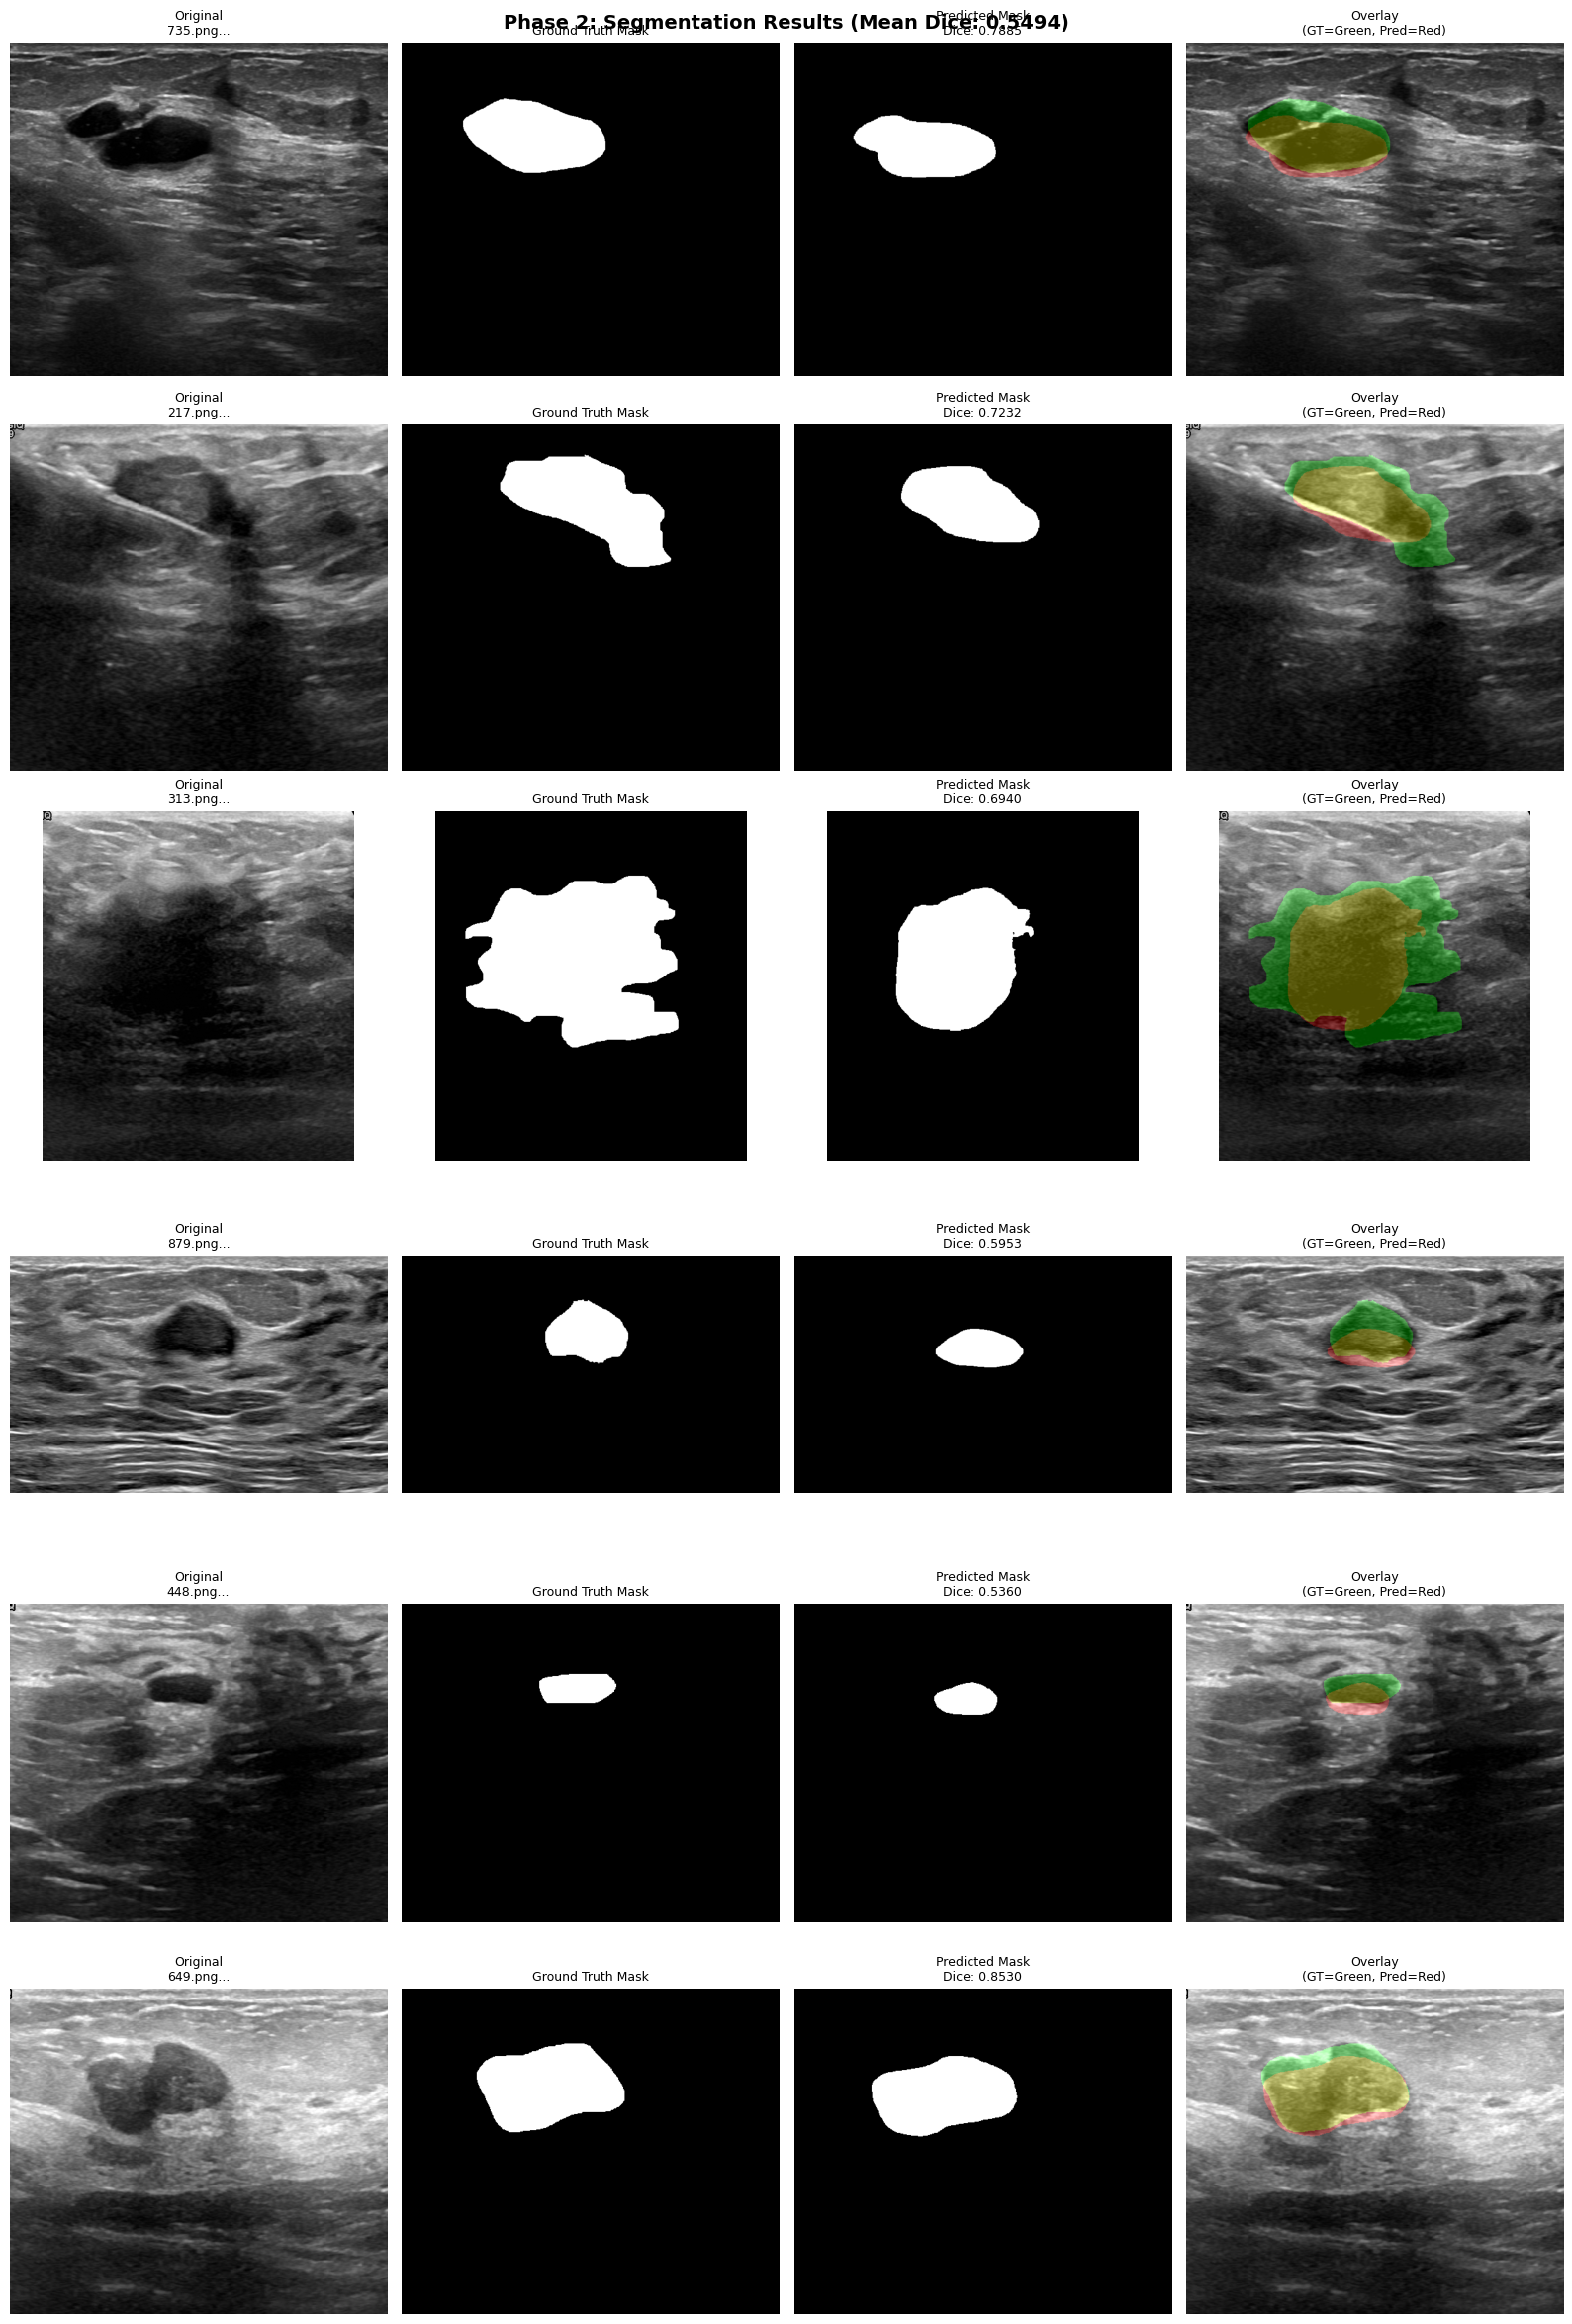

✅ Segmentation visualization complete


In [19]:
n_vis = min(6, len(seg_samples))
vis_indices = np.random.choice(len(seg_samples), n_vis, replace=False)

fig, axes = plt.subplots(n_vis, 4, figsize=(16, 4*n_vis))
if n_vis == 1:
    axes = axes.reshape(1, -1)

for i, idx in enumerate(vis_indices):
    sample = seg_samples[idx]
    
    img_bgr = cv2.imread(sample['img_path'])
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    gt_mask = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)
    
    pred_mask_512 = sample['pred_mask_512']
    h_orig, w_orig = img_gray.shape
    pred_mask = cv2.resize(pred_mask_512, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    
    # 1. Original
    axes[i, 0].imshow(img_gray, cmap='gray')
    axes[i, 0].set_title(f'Original\n{sample["img_name"][:25]}...', fontsize=9)
    axes[i, 0].axis('off')
    
    # 2. Ground Truth Mask
    axes[i, 1].imshow(gt_mask, cmap='gray')
    axes[i, 1].set_title('Ground Truth Mask', fontsize=9)
    axes[i, 1].axis('off')
    
    # 3. Predicted Mask
    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title(f'Predicted Mask\nDice: {sample["dice_score"]:.4f}', fontsize=9)
    axes[i, 2].axis('off')
    
    # 4. Overlay (GT=Green, Pred=Red, Overlap=Yellow)
    img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)
    overlay = img_rgb.copy().astype(np.float32) / 255.0
    
    # GT in green
    gt_bool = gt_mask > 127
    overlay[gt_bool, 1] = np.minimum(overlay[gt_bool, 1] + 0.3, 1.0)
    
    # Pred in red
    pred_bool = pred_mask > 127
    overlay[pred_bool, 0] = np.minimum(overlay[pred_bool, 0] + 0.3, 1.0)
    
    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title('Overlay\n(GT=Green, Pred=Red)', fontsize=9)
    axes[i, 3].axis('off')

plt.suptitle(f'Phase 2: Segmentation Results (Mean Dice: {mean_dice:.4f})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Segmentation visualization complete")

---

# Final Summary

In [20]:
print(f"\n{'='*80}")
print(f"📋 TASK 1 INFERENCE - FINAL SUMMARY")
print(f"{'='*80}")

print(f"\n🔬 PHASE 1: CLASSIFICATION (3-Class)")
print(f"   Model: ResNeSt50 Ensemble ({len(clf_models)} models)")
print(f"   Total samples: {len(test_samples)}")
print(f"   ✅ Balanced Accuracy: {ba_3class:.4f} ({ba_3class*100:.2f}%)")

print(f"\n🎯 PHASE 2: SEGMENTATION (Benign/Malignant only)")
print(f"   Model: SegFormer Ensemble ({len(seg_models)} models)")
print(f"   Samples evaluated: {len(seg_samples)}")
print(f"   ✅ Mean Dice Score: {mean_dice:.4f}")

print(f"\n📊 OUTPUTS:")
print(f"   Classification DataFrame: task1_classification_results.csv")
print(f"   Columns: US, LABEL")

print(f"\n{'='*80}\n")

print("\n📋 Classification Results Preview:")
print(df_classification.head(10))


📋 TASK 1 INFERENCE - FINAL SUMMARY

🔬 PHASE 1: CLASSIFICATION (3-Class)
   Model: ResNeSt50 Ensemble (5 models)
   Total samples: 308
   ✅ Balanced Accuracy: 0.8227 (82.27%)

🎯 PHASE 2: SEGMENTATION (Benign/Malignant only)
   Model: SegFormer Ensemble (2 models)
   Samples evaluated: 204
   ✅ Mean Dice Score: 0.5494

📊 OUTPUTS:
   Classification DataFrame: task1_classification_results.csv
   Columns: US, LABEL



📋 Classification Results Preview:
        US  LABEL
0  589.png      0
1  731.png      0
2  445.png      0
3  396.png      0
4  452.png      0
5  242.png      1
6  878.png      0
7  261.png      1
8  451.png      0
9  217.png      0



📊 DETAILED CLASSIFICATION ANALYSIS

Benign:
  Recall: 0.8657
  Precision: 0.8227
  TP: 116, FN: 18, FP: 25

Malignant:
  Recall: 0.6933
  Precision: 0.8254
  TP: 52, FN: 23, FP: 11

Normal:
  Recall: 0.9091
  Precision: 0.8654
  TP: 90, FN: 9, FP: 14



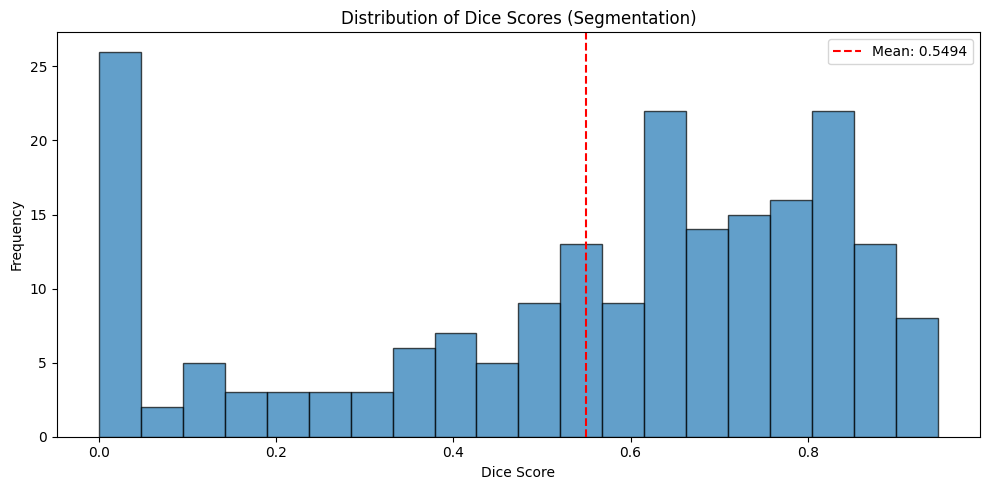

In [21]:
print(f"\n{'='*80}")
print(f"📊 DETAILED CLASSIFICATION ANALYSIS")
print(f"{'='*80}\n")

for class_idx, class_name in enumerate(['Benign', 'Malignant', 'Normal']):
    class_gt = [1 if gt == class_idx else 0 for gt in gt_labels]
    class_pred = [1 if pred == class_idx else 0 for pred in pred_labels]
    
    tp = sum(1 for g, p in zip(class_gt, class_pred) if g == 1 and p == 1)
    fn = sum(1 for g, p in zip(class_gt, class_pred) if g == 1 and p == 0)
    fp = sum(1 for g, p in zip(class_gt, class_pred) if g == 0 and p == 1)
    tn = sum(1 for g, p in zip(class_gt, class_pred) if g == 0 and p == 0)
    
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    
    print(f"{class_name}:")
    print(f"  Recall: {recall:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  TP: {tp}, FN: {fn}, FP: {fp}\n")

if len(dice_scores) > 0:
    plt.figure(figsize=(10, 5))
    plt.hist(dice_scores, bins=20, edgecolor='black', alpha=0.7)
    plt.axvline(mean_dice, color='red', linestyle='--', label=f'Mean: {mean_dice:.4f}')
    plt.xlabel('Dice Score')
    plt.ylabel('Frequency')
    plt.title('Distribution of Dice Scores (Segmentation)')
    plt.legend()
    plt.tight_layout()
    plt.show()